# Question 2: Models, Enhancement and Deployment

Flow: train four models and compare with the baseline (2.1), improve the best with hyper-parameter tuning (2.2), save the best configuration for the web interface (2.3).

In [1]:
import sys, joblib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
sys.path.append('../deployment')
from text_utils import clean_text

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

## Start from the data frame of Question 1

Same cleaned data and the same split (`random_state=42`).

In [2]:
df = pd.read_csv('../data/abstracts_clean.csv')
df['clean'] = df['clean'].fillna('')
df['target'] = (df['Label'] == 'ai').astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    df['clean'], df['target'], test_size=0.2, stratify=df['target'], random_state=42)
cv = StratifiedKFold(5, shuffle=True, random_state=42)

## 2.1 Four models versus the baseline

Every model uses the same TF-IDF features. Because the AI class is the minority and the one the service cares about, the main metric is the **F1 score of the AI class** (also cross-validated on the training data, so the model is not chosen on the test set).

In [3]:
models = {
    'Baseline: Multinomial NB': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Linear SVM': LinearSVC(class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42),
    'Complement NB': ComplementNB(),
}
rows = []
for name, clf in models.items():
    pipe = Pipeline([('tfidf', TfidfVectorizer(min_df=2, sublinear_tf=True)), ('clf', clf)])
    cv_f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1').mean()
    pipe.fit(X_train, y_train)
    p_tr, p_te = pipe.predict(X_train), pipe.predict(X_test)
    rows.append({'Model': name,
                 'Train acc': accuracy_score(y_train, p_tr), 'Test acc': accuracy_score(y_test, p_te),
                 'Precision (AI)': precision_score(y_test, p_te), 'Recall (AI)': recall_score(y_test, p_te),
                 'Test F1 (AI)': f1_score(y_test, p_te), 'CV F1 (AI)': cv_f1})
results = pd.DataFrame(rows).set_index('Model').round(3)
results

,Train acc,Test acc,Precision (AI),Recall (AI),Test F1 (AI),CV F1 (AI)
Model,,,,,,
Baseline: Multinomial NB,0.858,0.813,1.000,0.106,0.192,0.180
Logistic Regression,0.982,0.858,0.647,0.702,0.673,0.753
Linear SVM,0.999,0.893,0.811,0.638,0.714,0.815
Random Forest,1.000,0.893,0.767,0.702,0.733,0.785
Complement NB,0.957,0.889,0.893,0.532,0.667,0.658


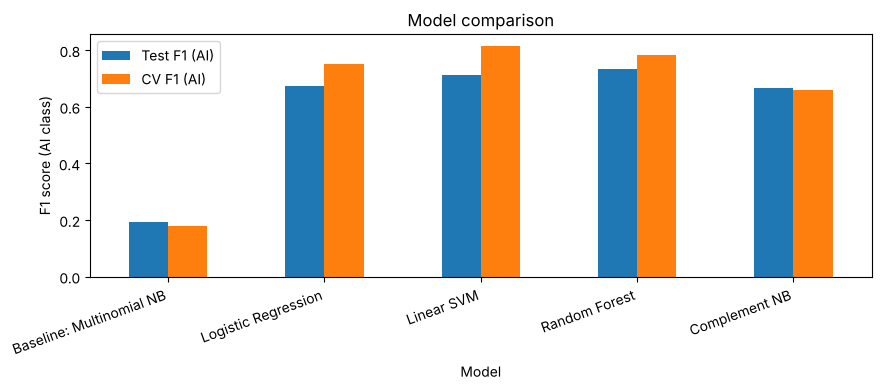

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
results[['Test F1 (AI)', 'CV F1 (AI)']].plot(kind='bar', ax=ax)
ax.set_ylabel('F1 score (AI class)'); ax.set_title('Model comparison')
plt.xticks(rotation=20, ha='right'); plt.tight_layout(); plt.show()

### Comment

- All four models clearly beat the baseline, whose AI-class F1 is about 0.19. Class weighting and richer decision boundaries are what the baseline lacked.
- Test F1 for the AI class: Random Forest about 0.73, Linear SVM about 0.71, Logistic Regression and Complement NB about 0.67. Cross-validated F1 (more reliable, because it uses many splits): **Linear SVM about 0.82**, Random Forest about 0.79, Logistic Regression about 0.75, Complement NB about 0.66. Linear SVM and Random Forest are close, and the test set contains only 47 AI abstracts, so a few abstracts move F1 by several points.
- Linear SVM and Random Forest reach almost 100% training accuracy against about 89% on the test set, which is some over-fitting. Complement NB has the lowest AI recall (about 0.53), so it misses the most AI abstracts.

## 2.2 Enhancement: hyper-parameter tuning with cross-validation

Besides changing the model, we tune it. A grid search with 5-fold cross-validation searches the regularisation strength `C`, the n-gram range (single words vs words and word pairs) and the minimum document frequency for the two strongest linear models. Selection uses cross-validated F1 on the training data only.

In [5]:
def tune(clf, c_values):
    pipe = Pipeline([('tfidf', TfidfVectorizer(sublinear_tf=True)), ('clf', clf)])
    grid = {'clf__C': c_values, 'tfidf__ngram_range': [(1, 1), (1, 2)], 'tfidf__min_df': [1, 2]}
    return GridSearchCV(pipe, grid, scoring='f1', cv=cv, n_jobs=-1).fit(X_train, y_train)

tuned = {
    'Logistic Regression (tuned)': tune(LogisticRegression(max_iter=2000, class_weight='balanced'), [0.5, 1, 3, 10, 30]),
    'Linear SVM (tuned)': tune(LinearSVC(class_weight='balanced'), [0.1, 0.3, 1, 3, 10]),
}
rows = []
for name, gs in tuned.items():
    pred = gs.predict(X_test)
    rows.append({'Model': name, 'Best parameters': gs.best_params_, 'CV F1 (AI)': round(gs.best_score_, 3),
                 'Test acc': round(accuracy_score(y_test, pred), 3), 'Test F1 (AI)': round(f1_score(y_test, pred), 3)})
pd.DataFrame(rows).set_index('Model')

,Best parameters,CV F1 (AI),Test acc,Test F1 (AI)
Model,,,,
Logistic Regression (tuned),"{'clf__C': 30, 'tfidf__min_df': 2, 'tfidf__ngr...",0.816,0.889,0.706
Linear SVM (tuned),"{'clf__C': 1, 'tfidf__min_df': 2, 'tfidf__ngra...",0.815,0.893,0.714


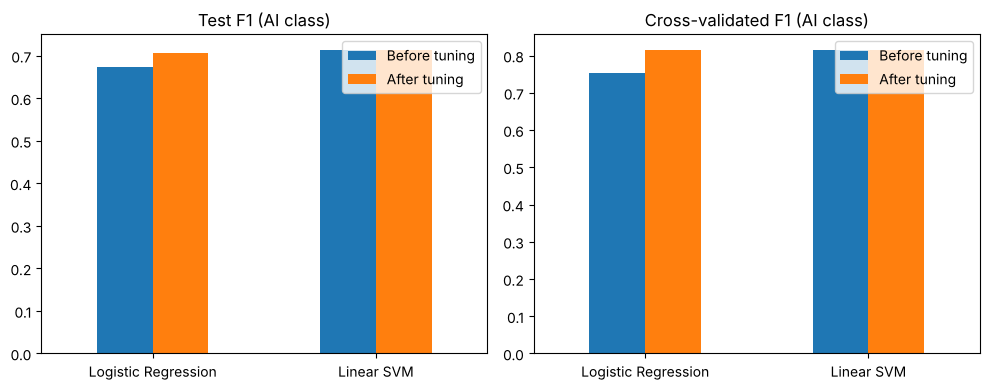

                     Before tuning  After tuning
Logistic Regression          0.673         0.706
Linear SVM                   0.714         0.714
                     Before tuning  After tuning
Logistic Regression          0.753         0.816
Linear SVM                   0.815         0.815


In [6]:
# Before vs after tuning (test F1 and cross-validated F1 of the AI class)
compare = pd.DataFrame({
    'Before tuning': [results.loc['Logistic Regression', 'Test F1 (AI)'], results.loc['Linear SVM', 'Test F1 (AI)']],
    'After tuning': [f1_score(y_test, tuned['Logistic Regression (tuned)'].predict(X_test)),
                     f1_score(y_test, tuned['Linear SVM (tuned)'].predict(X_test))],
}, index=['Logistic Regression', 'Linear SVM'])
cv_compare = pd.DataFrame({
    'Before tuning': [results.loc['Logistic Regression', 'CV F1 (AI)'], results.loc['Linear SVM', 'CV F1 (AI)']],
    'After tuning': [tuned['Logistic Regression (tuned)'].best_score_, tuned['Linear SVM (tuned)'].best_score_],
}, index=['Logistic Regression', 'Linear SVM'])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
compare.plot(kind='bar', ax=axes[0], title='Test F1 (AI class)', rot=0)
cv_compare.plot(kind='bar', ax=axes[1], title='Cross-validated F1 (AI class)', rot=0)
plt.tight_layout(); plt.show()
print(compare.round(3)); print(cv_compare.round(3))

### Comment

Tuning helps Logistic Regression most: its cross-validated F1 rises from about 0.75 to 0.82 and its test F1 from about 0.67 to 0.71. The search picked a large `C` (weaker regularisation) so the model can fit the vocabulary more closely. Linear SVM was already well configured, so tuning leaves its scores about the same (cross-validated F1 about 0.82). After tuning, Logistic Regression and Linear SVM are practically tied on cross-validated F1 (0.816 vs 0.815). With only 47 AI abstracts in the test set, differences this small are not reliable, which is why selection uses cross-validation.

## 2.3 Best configuration for deployment

The tuned model with the highest **cross-validated** F1 is chosen (not the test score, to avoid picking the model that happens to suit this one test split). The pipeline is saved for the Streamlit app in `../deployment`.

Best: Logistic Regression (tuned) {'clf__C': 30, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}
                         precision    recall  f1-score   support

     classical research       0.91      0.96      0.93       178
artificial intelligence       0.79      0.64      0.71        47

               accuracy                           0.89       225
              macro avg       0.85      0.80      0.82       225
           weighted avg       0.88      0.89      0.88       225



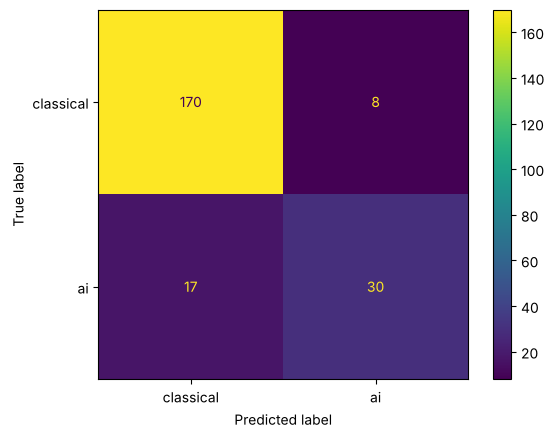

In [7]:
best_name = max(tuned, key=lambda k: tuned[k].best_score_)
best = tuned[best_name].best_estimator_
print('Best:', best_name, tuned[best_name].best_params_)

pred = best.predict(X_test)
print(classification_report(y_test, pred, target_names=['classical research', 'artificial intelligence']))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['classical', 'ai'])
plt.show()

In [8]:
joblib.dump(best, '../deployment/abstract_classifier.pkl')

# Quick test with the abstract from the brief (the app cleans text the same way)
sample = ('Artificial intelligence (AI) has become a transformative technology in healthcare by enabling '
          'more accurate diagnosis, predictive analytics, and personalised treatment planning. Machine learning '
          'algorithms can analyse large volumes of medical data to identify patterns that assist clinicians.')
label = {1: 'artificial intelligence', 0: 'classical research'}
print('The abstract is classified as:', label[int(best.predict([clean_text(sample)])[0])])

The abstract is classified as: artificial intelligence


The web interface is the Streamlit app in `../deployment/app.py` (see `../deployment/README.md` for the steps). It loads the saved pipeline, cleans the entered abstract with the same `clean_text` function, and shows the prediction.